# Sleep Quality

## Imports

In [2]:
import sys
import os
import pandas as pd
import numpy as np
from skfuzzy.control import Rule

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from preprocessor import clean_missing_values
from mamdani_engine import GenericMamdaniEngine
from evaluation import (evaluate_regression, plot_regression_results, plot_membership_functions, plot_control_surface, plot_data_distributions, plot_universe_percentiles)

## Data Preprocessing

In [ ]:
# File paths
raw_path = '../data/raw/whoop_fitness_dataset_100k.csv'
processed_path = '../data/processed/whoop_clean.csv'

# Data Loading & Preprocessing using the general preprocessor
if not os.path.exists(processed_path):
    print("Loading raw data and applying general preprocessing...")
    df_raw = pd.read_csv(raw_path)
    selected_cols = ['hrv', 'day_strain', 'wake_ups', 'sleep_efficiency']
    df_subset = df_raw[selected_cols].copy()
    
    df_clean = clean_missing_values(df_subset, subset_columns=selected_cols)
    
    os.makedirs(os.path.dirname(processed_path), exist_ok=True)
    df_clean.to_csv(processed_path, index=False)
    print(f"Clean dataset saved to: {processed_path}")
else:
    print("Loading preprocessed dataset...")
    df_clean = pd.read_csv(processed_path)

print(f"Dataset shape: {df_clean.shape}")
df_clean.head()
##

Loading preprocessed dataset...
Dataset shape: (100000, 4)


,hrv,day_strain,wake_ups,sleep_efficiency
0,118.3,7.33,1,72.3
1,105.7,10.38,1,78.3
2,95.3,7.16,0,78.8
3,76.2,16.47,0,80.3
4,94.4,16.67,0,73.0


## Data Distribution Analysis & Universe Calibration

HRV Universe: [20.0, 150.0]
Day Strain Universe: [0.0, 21.0]
Wake-ups Universe: [0, 7]
Sleep Efficiency Percentiles -> Min: 50.0, Q1: 76.5, Median: 85.0, Q3: 90.5, Max: 100.0
--- Feature Distributions Analysis ---


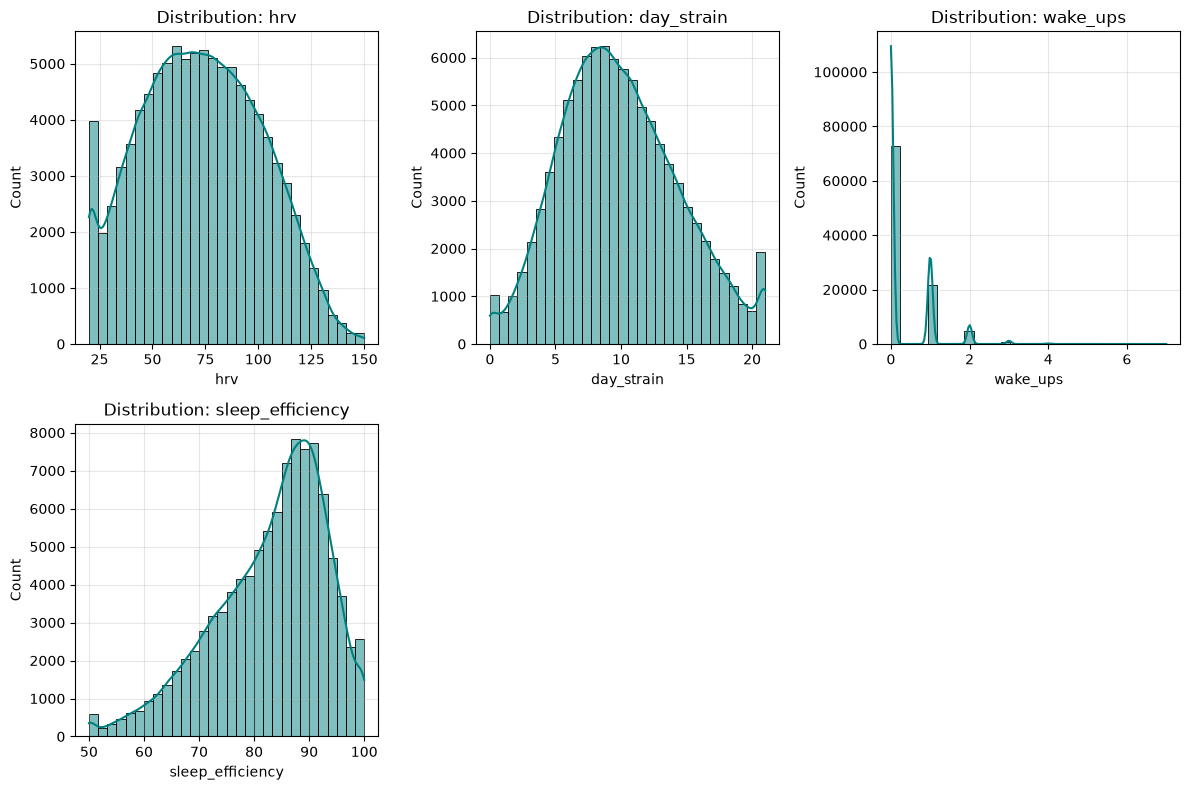

--- Target Consequent Percentile Calibration ---


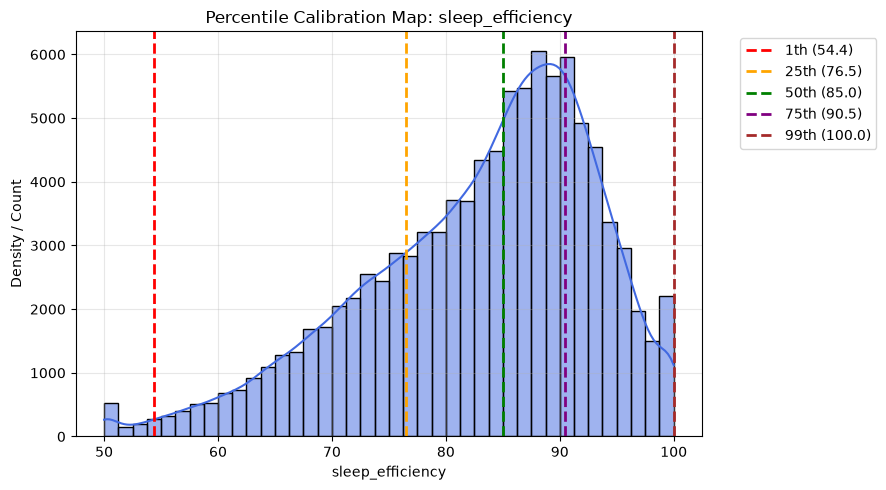

In [4]:
# Extract statistical bounds and percentiles from the real-world dataset
hrv_min, hrv_max = float(df_clean['hrv'].min()), float(df_clean['hrv'].max())
strain_min, strain_max = float(df_clean['day_strain'].min()), float(df_clean['day_strain'].max())
wake_min, wake_max = int(df_clean['wake_ups'].min()), int(df_clean['wake_ups'].max())

# Sleep efficiency bounds calibrated to full empirical data range [50.0, 100.0]
eff_min = 50.0
eff_q1 = float(df_clean['sleep_efficiency'].quantile(0.25))
eff_median = float(df_clean['sleep_efficiency'].quantile(0.50))
eff_q3 = float(df_clean['sleep_efficiency'].quantile(0.75))
eff_max = 100.0

print(f'HRV Universe: [{hrv_min}, {hrv_max}]')
print(f'Day Strain Universe: [{strain_min}, {strain_max}]')
print(f'Wake-ups Universe: [{wake_min}, {wake_max}]')
print(f'Sleep Efficiency Percentiles -> Min: {eff_min}, Q1: {eff_q1}, Median: {eff_median}, Q3: {eff_q3}, Max: {eff_max}')

# Inspect overall distributions for all input features and target
print('--- Feature Distributions Analysis ---')
plot_data_distributions(df_clean, columns=['hrv', 'day_strain', 'wake_ups', 'sleep_efficiency'])

# Inspect percentile breakdowns specifically for target output universe calibration
print('--- Target Consequent Percentile Calibration ---')
plot_universe_percentiles(df_clean, target_col='sleep_efficiency', percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])


## Mamdani FIS Configuration & Membership Functions

--- Generare Grafice Funcții de Apartenență (Antecedente) ---


c:\Users\david\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


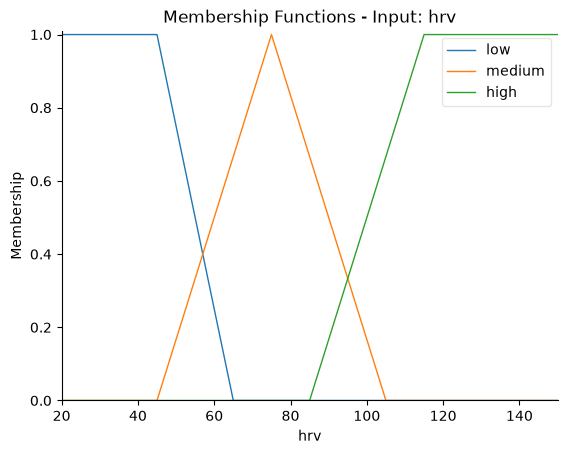

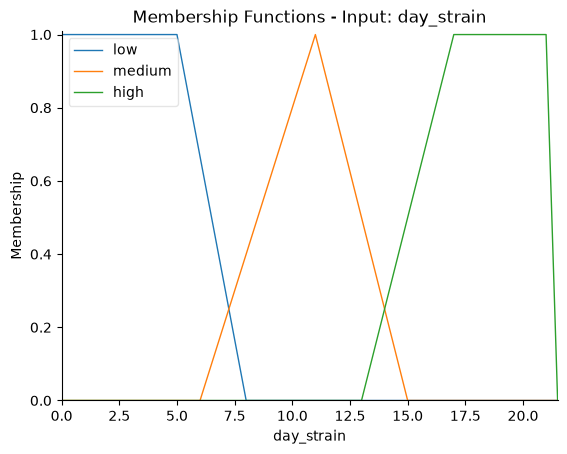

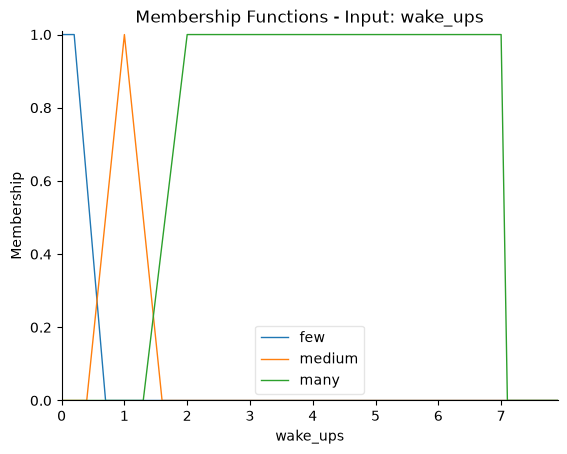

--- Generare Grafice Funcții de Apartenență (Consecvent) ---


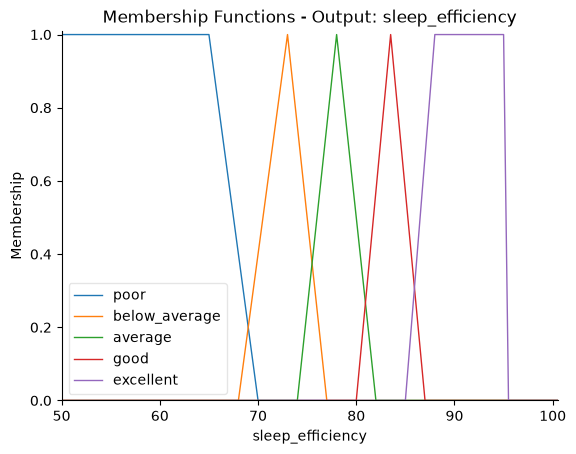

In [5]:
# Instantiate Mamdani Engine
fis = GenericMamdaniEngine()

# Define Antecedents (Inputs) calibrated to biological boundaries
fis.add_antecedent(
    'hrv',
    np.arange(int(hrv_min), int(hrv_max) + 1, 1),
    {
        'low': [20.0, 20.0, 45.0, 65.0],
        'medium': [45.0, 75.0, 105.0],
        'high': [85.0, 115.0, 150.0, 150.0]
    }
)

fis.add_antecedent(
    'day_strain',
    np.arange(int(strain_min), int(strain_max) + 1, 0.5),
    {
        'low': [0.0, 0.0, 5.0, 8.0],
        'medium': [6.0, 11.0, 15.0],
        'high': [13.0, 17.0, 21.0, 21.0]
    }
)

fis.add_antecedent(
    'wake_ups',
    np.arange(0, 8, 0.1),
    {
        'few': [0.0, 0.0, 0.2, 0.7],
        'medium': [0.4, 1.0, 1.6],
        'many': [1.3, 2.0, 7.0, 7.0]
    }
)

# Define Consequent (Output) with 5 continuous terms across full [50.0, 100.0] range
fis.add_consequent(
    'sleep_efficiency',
    np.arange(int(eff_min), int(eff_max) + 1, 0.5),
    {
        'poor': [50.0, 50.0, 65.0, 70.0],
        'below_average': [68.0, 73.0, 77.0],
        'average': [74.0, 78.0, 82.0],
        'good': [80.0, 83.5, 87.0],
        'excellent': [85.0, 88.0, 95.0, 95.0]
    }
)

# Visualize Membership Functions
plot_membership_functions(fis)


## IF-THEN Rules Definition

In [6]:
# # Definition of all 27 IF-THEN Rules (Complete combinatorial rule base)
# ant = fis.antecedents
# cons = fis.consequents

# # single rule system
# rules = [
#     # HRV = Low
#     Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    
#     # HRV = Medium
#     Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    
#     # HRV = High
#     Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
#     Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor'])
# ]

# # Build control system with all 27 rules
# fis.build_system(rules)
# print(f"Mamdani control system successfully built with {len(rules)} rules!")

In [7]:
ant = fis.antecedents
cons = fis.consequents

# Biologically accurate 3D rule matrix (27 rules) with 5-term consequent
rule_matrix = {
    'few': {
        'low':    {'low': 'below_average', 'medium': 'average',       'high': 'below_average'},
        'medium': {'low': 'average',       'medium': 'good',          'high': 'average'},
        'high':   {'low': 'good',          'medium': 'excellent',     'high': 'good'}
    },
    'medium': {
        'low':    {'low': 'poor',          'medium': 'below_average', 'high': 'poor'},
        'medium': {'low': 'below_average', 'medium': 'average',       'high': 'below_average'},
        'high':   {'low': 'average',       'medium': 'good',          'high': 'average'}
    },
    'many': {
        'low':    {'low': 'poor',          'medium': 'poor',          'high': 'poor'},
        'medium': {'low': 'poor',          'medium': 'below_average', 'high': 'poor'},
        'high':   {'low': 'below_average', 'medium': 'below_average', 'high': 'poor'}
    }
}

# Rules list from the updated matrix
rules = []
table_data = []

rule_count = 1
for wake_level, hrv_dict in rule_matrix.items():
    for hrv_level, strain_dict in hrv_dict.items():
        for strain_level, outcome in strain_dict.items():
            # Create and store the actual rule object for the code
            rule = Rule(
                ant['hrv'][hrv_level] & ant['day_strain'][strain_level] & ant['wake_ups'][wake_level], 
                cons['sleep_efficiency'][outcome]
            )
            rules.append(rule)
            
            # Collect data for the dataframe
            table_data.append({
                "Rule": rule_count,
                "HRV": hrv_level,
                "Day Strain": strain_level,
                "Wake-ups": wake_level,
                "Sleep Efficiency (Consequent)": outcome
            })
            rule_count += 1

df = pd.DataFrame(table_data)
pd.set_option('display.max_rows', None)

# Build control system with all 27 rules
fis.build_system(rules)
print(f"Mamdani control system successfully built with {len(rules)} rules!")

df


Mamdani control system successfully built with 27 rules!


,Rule,HRV,Day Strain,Wake-ups,Sleep Efficiency (Consequent)
0,1,low,low,few,below_average
1,2,low,medium,few,average
2,3,low,high,few,below_average
3,4,medium,low,few,average
4,5,medium,medium,few,good
5,6,medium,high,few,average
6,7,high,low,few,good
7,8,high,medium,few,excellent
8,9,high,high,few,good
9,10,low,low,medium,poor


## Running Inference on Dataset

In [8]:
# Run Inference on a representative random i.i.d. sample of the clean dataset
df_sample = df_clean.sample(500, random_state=42).copy()
input_features = ['hrv', 'day_strain', 'wake_ups']

print("Running fuzzy inference on dataset...")
y_pred = fis.predict_dataset(df_sample, input_features)
y_true = df_sample['sleep_efficiency'].values

# Filter out potential NaNs
valid_idx = ~np.isnan(y_pred)
y_true_clean = y_true[valid_idx]
y_pred_clean = y_pred[valid_idx]

print(f"Inference complete for {len(y_pred_clean)} valid samples.")


Running fuzzy inference on dataset...
Inference complete for 500 valid samples.


## Evaluation and Visualization

--- Quantitative Error Metrics Table ---


,Metric,Value
0,MAE (Mean Absolute Error),10.201904
1,MSE (Mean Squared Error),148.443482
2,RMSE (Root Mean Squared Error),12.183738
3,R2 Score,-0.438921


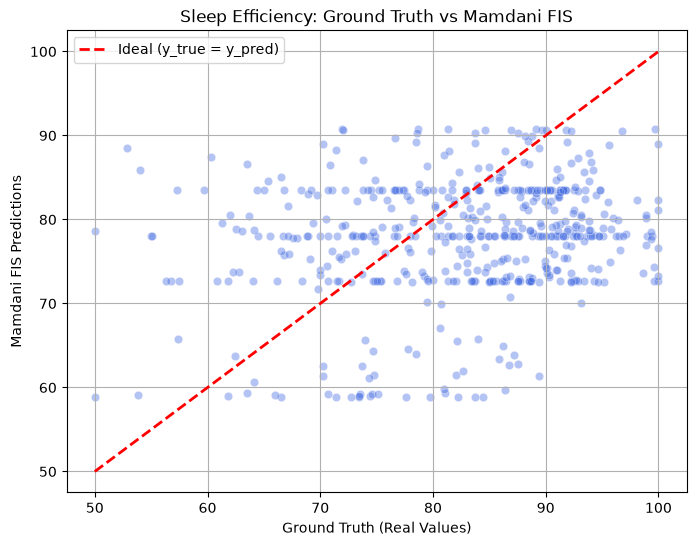

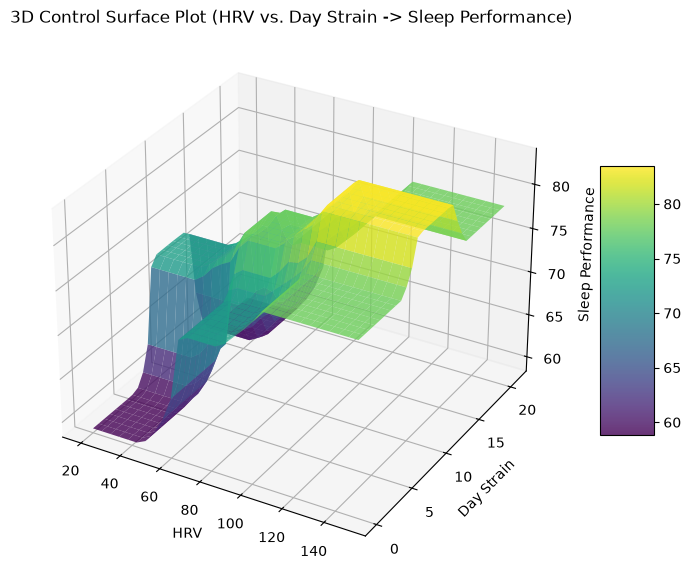

In [9]:
# 1. Quantitative Error Table
metrics_df = evaluate_regression(y_true_clean, y_pred_clean)
print("--- Quantitative Error Metrics Table ---")
display(metrics_df)

# 2. Regression Scatter Plot (Real vs Predicted)
plot_regression_results(y_true_clean, y_pred_clean, title='Sleep Efficiency: Ground Truth vs Mamdani FIS')

# 3. 3D Control Surface Plot
plot_control_surface(fis.simulation, 'hrv', 'day_strain', 'sleep_efficiency')
